In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
df = pd.read_csv('02 brainstroke.csv', usecols = ['age', 'avg_glucose_level', 'bmi', 'stroke'])

In [3]:
df.sample(10)

,age,avg_glucose_level,bmi,stroke
2058,52.0,94.98,23.8,0
1555,5.0,82.41,18.4,0
3343,9.0,61.75,16.2,0
824,38.0,76.82,27.3,0
3310,34.0,112.72,19.4,0
3196,14.0,137.91,41.8,0
1604,47.0,65.04,30.9,0
4246,12.0,108.63,23.4,0
2302,37.0,87.16,30.4,0
278,70.0,214.45,31.2,0


In [4]:
df.isnull().sum()

age                    0
avg_glucose_level      0
bmi                  201
stroke                 0
dtype: int64

In [5]:
# Filling missing values on bmi column.

from sklearn.impute import KNNImputer

In [7]:
knni = KNNImputer(n_neighbors = 5)

df['bmi'] = knni.fit_transform(df[['bmi']])

In [8]:
df.isnull().sum()

age                  0
avg_glucose_level    0
bmi                  0
stroke               0
dtype: int64

In [9]:
df.stroke.value_counts()

0    4861
1     249
Name: stroke, dtype: int64

In [22]:
# Here we can see in the above code that our class is imbalaced. So let's first balance it.

unique_class = df.stroke.unique()
sampled_df = []

for value in unique_class:
    subset = df[df['stroke'] == value]
    sample = subset.sample(min(250, len(subset)), replace = False)
    sampled_df.append(sample)

In [24]:
# Concenating the sampled_df

new_df = pd.concat(sampled_df, ignore_index = True)

In [25]:
new_df.stroke.value_counts()

0    250
1    249
Name: stroke, dtype: int64

# Train/Test split

In [53]:
x = new_df.drop(columns = 'stroke', axis = 'columns')
y = new_df.drop(x, axis = 'columns')

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

# Plotting distplot and QQ plot before PowerTransfprmer.

C:\Users\jugal\AppData\Local\Temp\ipykernel_13120\2124021011.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ipykernel_13120\2124021011.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ip

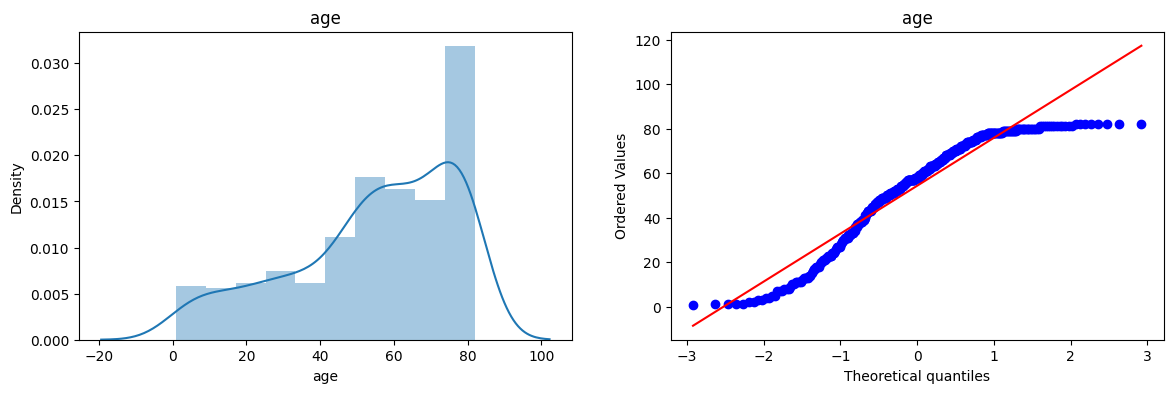

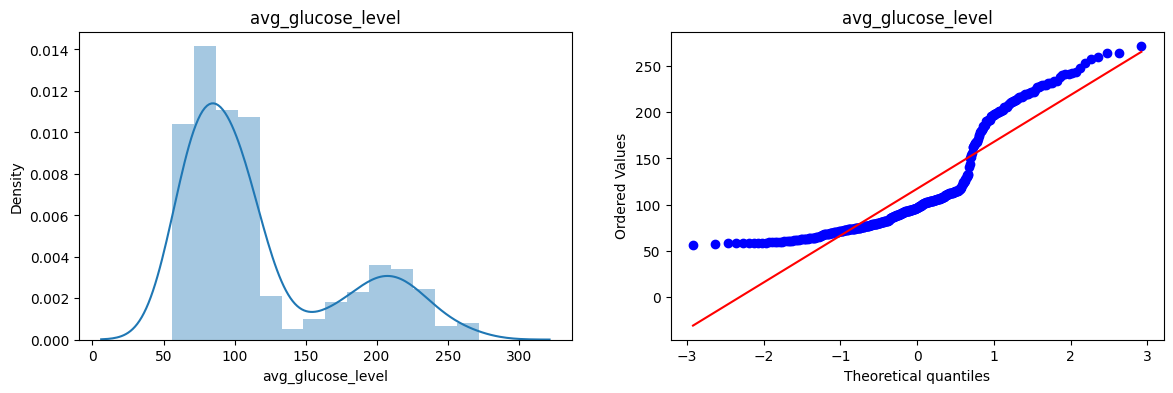

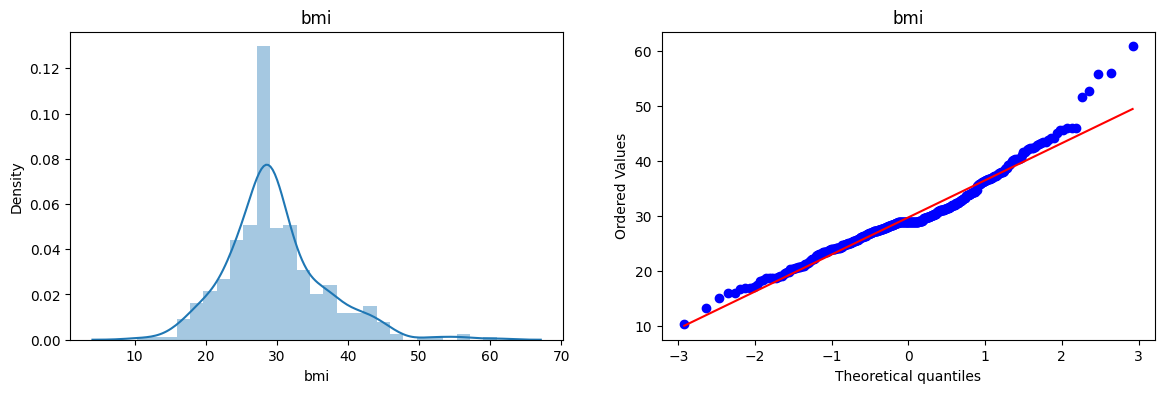

In [56]:
for column in x_train.columns:
    plt.figure(figsize = (14, 4))

    plt.subplot(121)
    sns.distplot(x_train[column])
    plt.title(column)

    plt.subplot(122)
    stats.probplot(x_train[column], dist = 'norm', plot = plt)
    plt.title(column)

# Linear regression before `PowerTransformer`.

In [81]:
from sklearn.linear_model import LinearRegression

In [84]:
lr = LinearRegression()

In [85]:
lr.fit(x_train, y_train)

LinearRegression()

In [86]:
pred = lr.predict(x_test)

In [89]:
from sklearn.metrics import r2_score

In [90]:
r2_score_b4 = r2_score(pred, y_test)
r2_score_b4

-1.1109675837445407

In [69]:
# Applying cross validation.

from sklearn.model_selection import cross_val_score

In [91]:
cross_val_score(estimator = lr, X = x_train, y = y_train, cv = 10, scoring = 'r2').mean()

0.29988728210380966

# After `PowerTransformer`.

In [92]:
from sklearn.preprocessing import PowerTransformer

In [93]:
pt = PowerTransformer(method = 'yeo-johnson')

In [94]:
x_train_trans = pt.fit_transform(x_train)
x_test_trans = pt.transform(x_test)

In [95]:
# Let's see which value for lambda it selected.

data = {'Columns': x_train.columns, 'yeo-johnson lambda': pt.lambdas_}

pd.DataFrame(data)

,Columns,yeo-johnson lambda
0,age,1.356294
1,avg_glucose_level,-0.888458
2,bmi,0.202088


In [96]:
# Converting to DataFrame
x_train_trans_df = pd.DataFrame(x_train_trans, columns = x_train.columns)
x_test_trans_df = pd.DataFrame(x_test_trans, columns = x_test.columns)

# Distplot before and after `PowerTransformer`.

C:\Users\jugal\AppData\Local\Temp\ipykernel_13120\2915040785.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ipykernel_13120\2915040785.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train_trans_df[column])
C:\Users\jugal\AppData\Loca

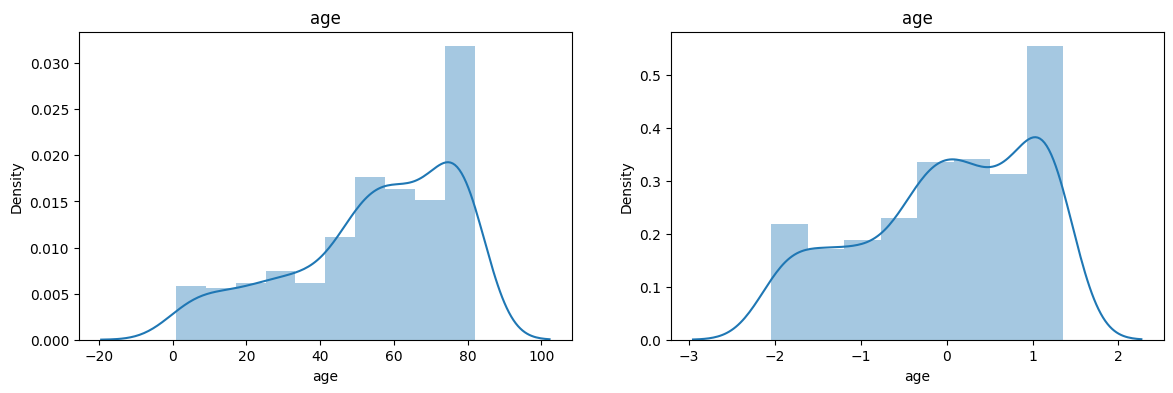

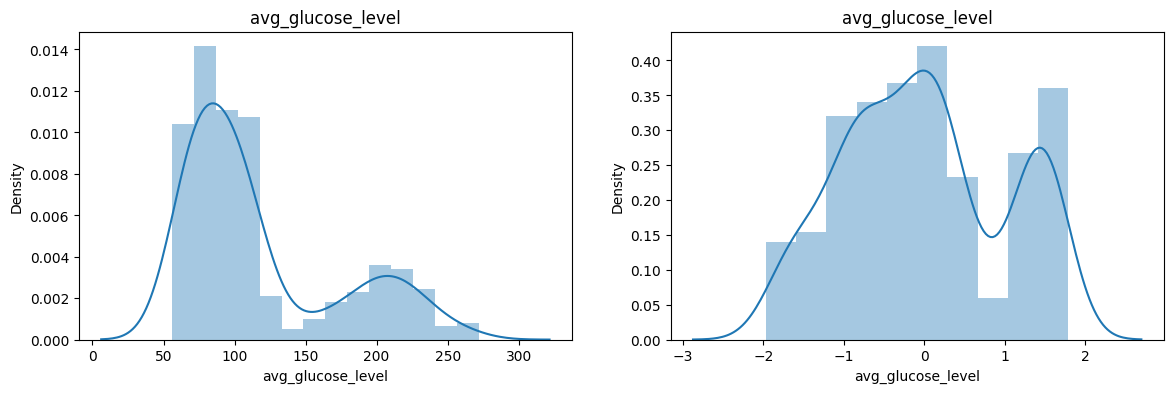

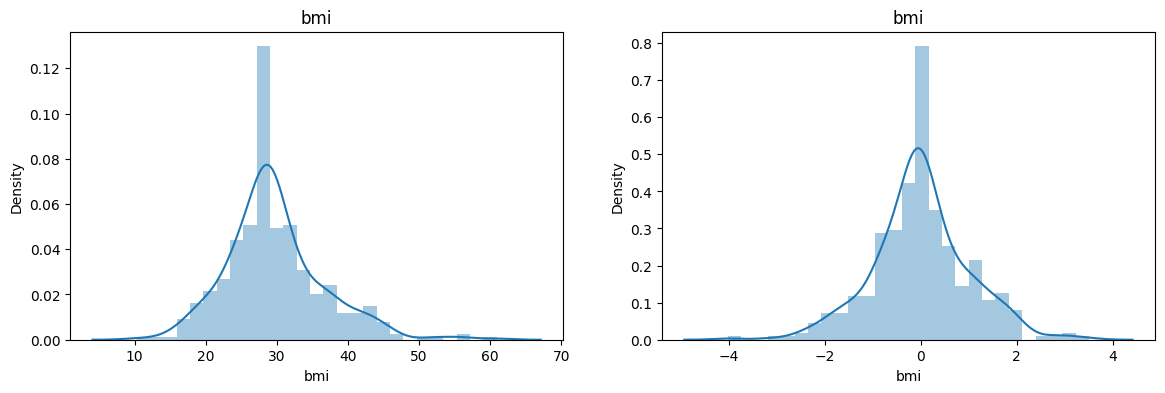

In [97]:
for column in x_train.columns:
    plt.figure(figsize = (14, 4))

    plt.subplot(121)
    sns.distplot(x_train[column])
    plt.title(column)

    plt.subplot(122)
    sns.distplot(x_train_trans_df[column])
    plt.title(column)

In [98]:
# Model after PowerTransformer.

lr.fit(x_train_trans, y_train)

LinearRegression()

In [99]:
pred_after = lr.predict(x_test_trans)

In [100]:
r2_score_after = r2_score(pred_after, y_test)
r2_score_after

-1.0115590133908787